In [30]:
import os
import sys
import pandas as pd
import numpy as np
import time
import joblib
import umap

from matplotlib import pyplot as plt
from sklearn.neighbors import NearestNeighbors
from kneed import KneeLocator
from sklearn.cluster import DBSCAN


sys.path.insert(0, '../../..') # Load Parent directory to import utils
from utils.helper_functions import normalize_series
from utils.constants import Configs
from utils.helper_functions import load_outlier_data
from utils.plotting import plot_movement_data
from utils.plotting import plot_movement_data_3d
from utils.plotting import plot_dimesionality_reduction_outliers

# Define the target movement for anomaly detection
TARGET_MOVEMENT = 'Place' 

In [31]:
# Load the processed data from the csv
cache_path = Configs.SMART_RETAIL_FILTERED_DATA_BIMANUAL
if os.path.exists(cache_path):
    print(f"Loading processed data from {cache_path}")
    df = pd.read_csv(cache_path)
else:
    print(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

Loading processed data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/data/processed/filtered_data_bimanual.csv


In [32]:
print("\n--- Fusing Outliers into a singular Ground Truth ---")
    
# Load the known outliers from the csv
outliers_left_csv, total_known_outliers_left = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_LEFT_PATH)
outliers_right_csv, total_known_outliers_right = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_RIGHT_PATH)


outliers_bimanual = pd.concat([outliers_left_csv, outliers_right_csv])
total_known_outliers = len(outliers_bimanual)

# O drop_duplicates garante que se o sub 13 falhou com as duas mãos, conta como 1 erro
outliers_bimanual = outliers_bimanual.drop_duplicates(subset=['sub', 'repID']).copy()
total_known_outliers = len(outliers_bimanual)

print(f"Total de OUTLIERS BIMANUAIS (Ground Truth): {total_known_outliers}")


--- Fusing Outliers into a singular Ground Truth ---
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_left.csv
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_right.csv
Total de OUTLIERS BIMANUAIS (Ground Truth): 24


### Discard sub 13.
Aparently his movements were not good at all. The existance of those movements might influence the detection of other outliers 

In [33]:
# Discard from dataset
df.drop(df[df['sub']== 13].index, inplace=True)

# Discard from outliers csv
outliers_bimanual.drop(outliers_bimanual[outliers_bimanual['sub'] == 13].index, inplace=True)
outliers_bimanual[outliers_bimanual['sub'] == 13]

,sub,repID


In [34]:
# Making sure that the metadata is perfectly aligned with the movement data matrix (X_movement)
df = df.sort_values(by=['sub', 'repID', 'movID', 'step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

group_array = [
    'xs_L', 'ys_L', 'zs_L', 'xe_L', 'ye_L', 'ze_L', 'xw_L', 'yw_L', 'zw_L', # Braço Esquerdo
    'xs_R', 'ys_R', 'zs_R', 'xe_R', 'ye_R', 'ze_R', 'xw_R', 'yw_R', 'zw_R'  # Braço Direito
]
sample_size = None

X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, 18)

Processing time series: 100%|██████████| 360/360 [00:00<00:00, 3632.54it/s]


Shape of first series: (121, 18)
Shape of formatted series: (360, 2126, 18)


In [35]:
# =========================================================================
# A BASE DE CÁLCULO 
# =========================================================================

# Extrair os metadados diretamente da fonte da verdade
results_temp_base = df_filtered[['sub', 'repID', 'movID']].drop_duplicates().reset_index(drop=True)

# --- Parâmetros Dinâmicos (Limites de Lixo) ---
total_trials = len(results_temp_base)
known_outlier_rate = total_known_outliers / total_trials
percentagem_conhecida = known_outlier_rate * 100


if total_trials != X_movement.shape[0]:
    print(f"⚠️ ERRO CRÍTICO: Metadados ({total_trials}) não batem com Matriz ({X_movement.shape[0]})!")
else:
    print(f"✅ Sincronização Perfeita! Linhas na Matriz: {X_movement.shape[0]} | Linhas nos Metadados: {total_trials}")

✅ Sincronização Perfeita! Linhas na Matriz: 360 | Linhas nos Metadados: 360


## UMAP

In [36]:
print(f"\n--- A preparar dados para UMAP Bimanual ({TARGET_MOVEMENT}) ---")

# Extrair TODAS as 18 coordenadas
X_all = X_movement.copy() 
n_samples, n_timepoints, n_dims = X_all.shape  # n_dims será automaticamente 18

# LIMPEZA DE NaNs (Forward Fill - Obrigatório para PCA)
for i in range(n_samples):
    for j in range(n_dims):
        s = pd.Series(X_all[i, :, j])
        X_all[i, :, j] = s.ffill().bfill().values

# Concatenação (Esmagar de 3D para 2D)
# Passamos para uma matriz plana de (n_samples, n_timepoints * 18)
X_flat = np.transpose(X_all, (0, 2, 1)).reshape(n_samples, n_timepoints * n_dims)


--- A preparar dados para UMAP Bimanual (Place) ---


## DBSCAN

### Elbow Method Utility

In [37]:
def calculate_dynamic_eps(data: np.ndarray, k: int, plot: bool = False) -> float:
    """
    Calculates the optimal EPS for DBSCAN dynamically based on the k-distance graph.
    """
    nbrs = NearestNeighbors(n_neighbors=k)
    nbrs.fit(data)
    distances, _ = nbrs.kneighbors(data)
    
    # Sort distances to the k-th neighbor
    k_distances = np.sort(distances[:, k-1])
    
    x = range(len(k_distances))
    kneedle = KneeLocator(x, k_distances, curve='convex', direction='increasing')
    
    optimal_eps = kneedle.elbow_y
    
    # Fallback in case KneeLocator fails to find a distinct elbow
    if optimal_eps is None:
        optimal_eps = np.percentile(k_distances, 90) 
        
    if plot:
        plt.figure(figsize=(8, 4))
        plt.plot(x, k_distances, label=f'Distance to {k}th Neighbor')
        plt.axhline(y=optimal_eps, color='r', linestyle='--', label=f'EPS: {optimal_eps:.3f}')
        plt.title('Dynamic EPS Detection')
        plt.legend()
        plt.show()
        
    return optimal_eps

### Grid Search

In [38]:
min_n_components = 3
max_n_components = 10 
umap_neighbors_options = [5, 15] 

results_log = []

print("\n--- Starting Dynamic Grid Search (UMAP + DBSCAN) ---")

for u_neigh in umap_neighbors_options:
    for n_comp in range(min_n_components, max_n_components + 1):
        
        # 1. TRAIN UMAP
        umap_start_time = time.perf_counter()
        reducer = umap.UMAP(n_neighbors=u_neigh, n_components=n_comp, random_state=42)
        umap_scores = reducer.fit_transform(X_flat) # Assuming X_flat is your 2D flattened bimanual array
        umap_end_time = time.perf_counter()

        # 2. DYNAMIC DBSCAN PARAMETERS
        # Rule of thumb for DBSCAN: min_samples = 2 * dimensionality
        min_samples = n_comp * 2
        
        # Calculate optimal EPS for THIS specific UMAP projection
        eps_start_time = time.perf_counter()
        optimal_eps = calculate_dynamic_eps(umap_scores, k=min_samples)
        eps_end_time = time.perf_counter()
        
        # Test a small neighborhood around the mathematical optimum to ensure robust results
        eps_options = [optimal_eps * 0.9, optimal_eps, optimal_eps * 1.1]

        for eps_val in eps_options:
            dbscan_start_time = time.perf_counter()

            # 3. TRAIN DBSCAN
            model = DBSCAN(eps=eps_val, min_samples=min_samples, metric='euclidean')
            labels = model.fit_predict(umap_scores)
            dbscan_end_time = time.perf_counter()
        
            # DBSCAN labels: -1 are outliers, >= 0 are core/cluster samples
            # --- METRICS CALCULATION ---
            results_temp = results_temp_base.copy() # Assuming this DataFrame exists in your environment
            results_temp['label'] = labels
            
            real_outliers_info = results_temp[results_temp['label'] == -1]
            identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])
            
            matched_outliers = pd.merge(identified_unique, outliers_bimanual, on=['sub', 'repID'], how='inner')
            missing_outliers = pd.merge(outliers_bimanual, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
            missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']
            
            TP = len(matched_outliers)
            FP = len(identified_unique) - TP
            FN = len(missing_outliers)
            
            if (TP + FP) > 0:
                precision = (TP / (TP + FP)) * 100
                recall = (TP / total_known_outliers) * 100
                f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
                f2_score = (5 * precision * recall) / (4 * precision + recall) if (precision + recall) > 0 else 0
            else:
                precision, recall, f1_score, f2_score = 0.0, 0.0, 0.0, 0.0
                
            garbage_percentage = (len(identified_unique) / total_trials) * 100
            total_time = (umap_end_time - umap_start_time) + (eps_end_time - eps_start_time) + (dbscan_end_time - dbscan_start_time)
                
            results_log.append({
                'umap_neighbors': u_neigh,
                'n_components': n_comp,
                'min_samples': min_samples,
                'eps': round(eps_val, 3),
                'total_time': total_time,
                'Recall': recall,
                'Precision': precision,
                'F1-Score': f1_score,
                'F2-Score': f2_score,
                'TP': TP,
                'FP': FP,
                'FN': FN,
                'Garbage Percent': garbage_percentage
            })


--- Starting Dynamic Grid Search (UMAP + DBSCAN) ---


/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/hugo-guimar-es/Documents/GitHu

In [39]:
# --- SELEÇÃO DO MELHOR MODELO ---
results_df = pd.DataFrame(results_log)
limite_lixo = percentagem_conhecida + 5.0 
acceptable_models = results_df[results_df['Garbage Percent'] <= limite_lixo]

if acceptable_models.empty:
    print(f"⚠️ Aviso: Nenhum modelo conseguiu ter menos de {limite_lixo:.1f}% de lixo. A usar todos.")
    acceptable_models = results_df

best_results = acceptable_models.sort_values(by=['F2-Score', 'Garbage Percent'], ascending=[False, True])
best_params = best_results.iloc[0]

percentagem_lixo = best_params['Garbage Percent']
retencao = 100 - best_params['Garbage Percent']
print(f"--- Grid Search (UMAP + DBSCAN): ---")
print(f"UMAP Neighbors: {best_params['umap_neighbors']} | Components: {best_params['n_components']}")
print(f"DBSCAN EPS: {best_params['eps']} | Min Samples: {best_params['min_samples']}")
print(f"Precision: {best_params['Precision']:.2f}% | Recall: {best_params['Recall']:.2f}%")
print(f"F1-Score: {best_params['F1-Score']:.2f}% | F2-Score: {best_params['F2-Score']:.2f}%")
print(f"Retencao: {retencao:.2f}% | Lixo: {percentagem_lixo:.2f}%")
print(f"TP: {best_params['TP']} | FP: {best_params['FP']} | FN: {best_params['FN']}")
print(f"Total Time: {best_params['total_time']:.4f} segundos")

--- Grid Search (UMAP + DBSCAN): ---
UMAP Neighbors: 15.0 | Components: 6.0
DBSCAN EPS: 0.731 | Min Samples: 12.0
Precision: 54.55% | Recall: 25.00%
F1-Score: 34.29% | F2-Score: 28.04%
Retencao: 96.94% | Lixo: 3.06%
TP: 6.0 | FP: 5.0 | FN: 16.0
Total Time: 1.5343 segundos


### Treinar Modelo Final

In [40]:
print("\n--- A EXTRAIR AS TRAJETÓRIAS ANÓMALAS (VENCEDOR UMAP) ---")

# Restore the best parameters
best_u_neigh = int(best_params['umap_neighbors'])
best_n_comp = int(best_params['n_components'])

best_eps = best_params['eps']
best_min_samples = int(best_params['min_samples'])


# Re-train
reducer_final = umap.UMAP(n_neighbors=best_u_neigh, n_components=best_n_comp, random_state=42)
umap_scores_final = reducer_final.fit_transform(X_flat)

model_final = DBSCAN(eps=best_eps, min_samples=best_min_samples, metric='euclidean')
final_labels = model_final.fit_predict(umap_scores_final)

outlier_indices = np.where(final_labels == -1)[0]
inlier_indices = np.where(final_labels != -1)[0]

X_movement_clean = np.delete(X_movement, outlier_indices, axis=0)
X_movement_outliers = X_movement[outlier_indices]

print(f"Total de Repetições Analisadas: {len(X_movement)}")
print(f"Outliers Bimanuais Detetados: {len(outlier_indices)}")


--- A EXTRAIR AS TRAJETÓRIAS ANÓMALAS (VENCEDOR UMAP) ---


/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Total de Repetições Analisadas: 360
Outliers Bimanuais Detetados: 11


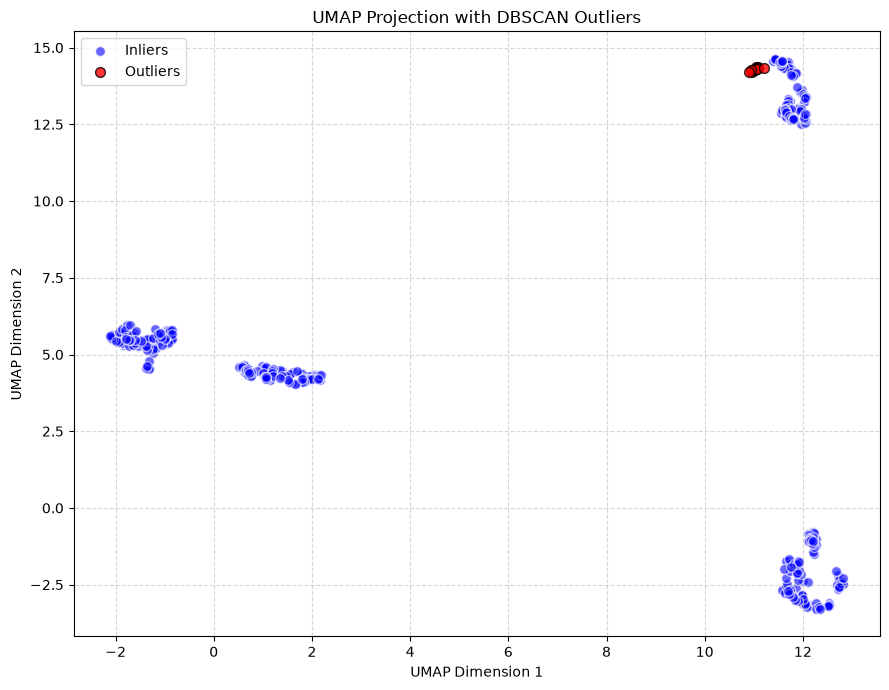

In [41]:
plot_dimesionality_reduction_outliers(umap_scores_final, outlier_indices, inlier_indices, "UMAP", "DBSCAN")

In [42]:
print("\n--- IDENTIDADE DOS OUTLIERS DETETADOS ---")

outliers_identificados = results_temp_base.iloc[outlier_indices].copy()

print(f"Encontrados {len(outliers_identificados)} outliers bimanuais:")
print(outliers_identificados[['sub', 'repID', 'movID']].to_string(index=False))


--- IDENTIDADE DOS OUTLIERS DETETADOS ---
Encontrados 11 outliers bimanuais:
 sub  repID  movID
   3      1      4
   3      2      4
   3      3      4
   3      4      4
   3      5      4
   4      1      4
   4      2      4
   4      3      4
   4      4      4
   4      5      4
   6      1      4


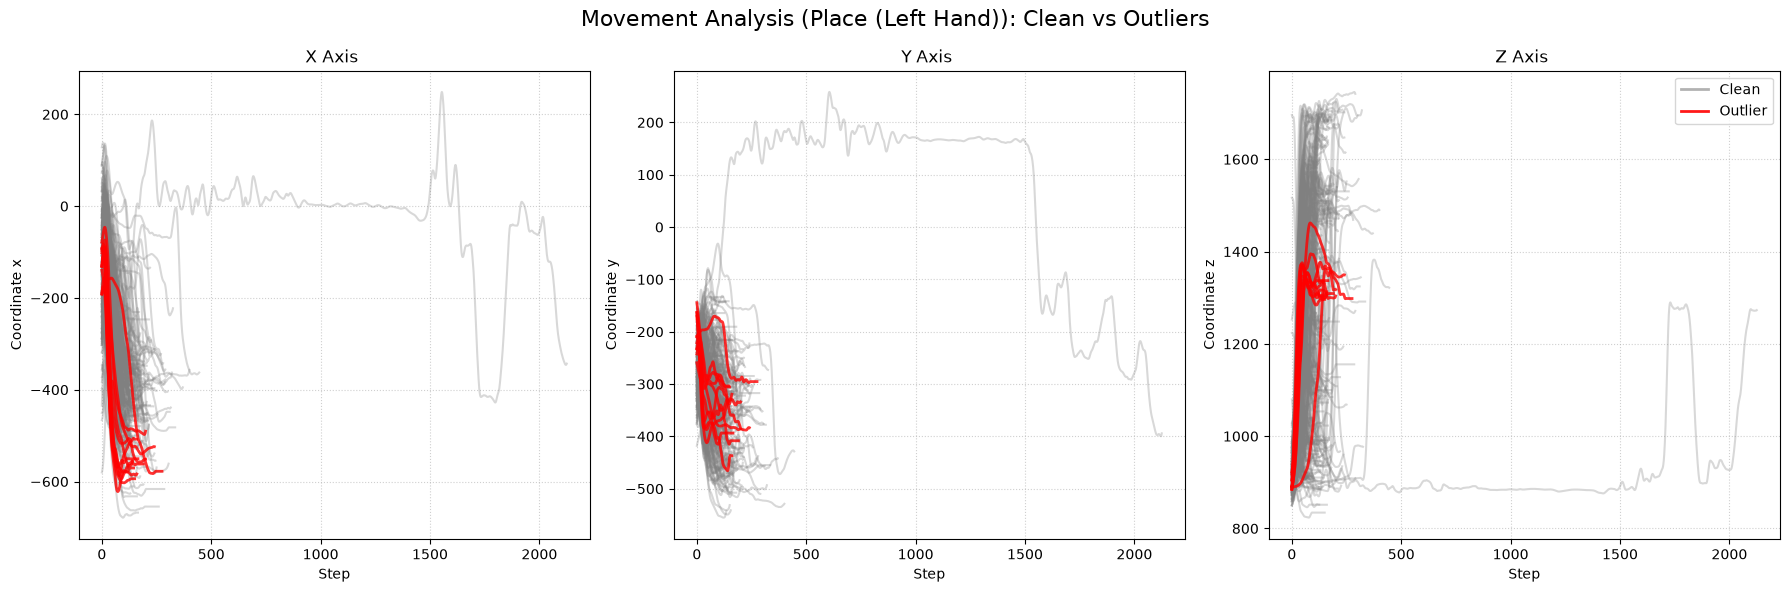

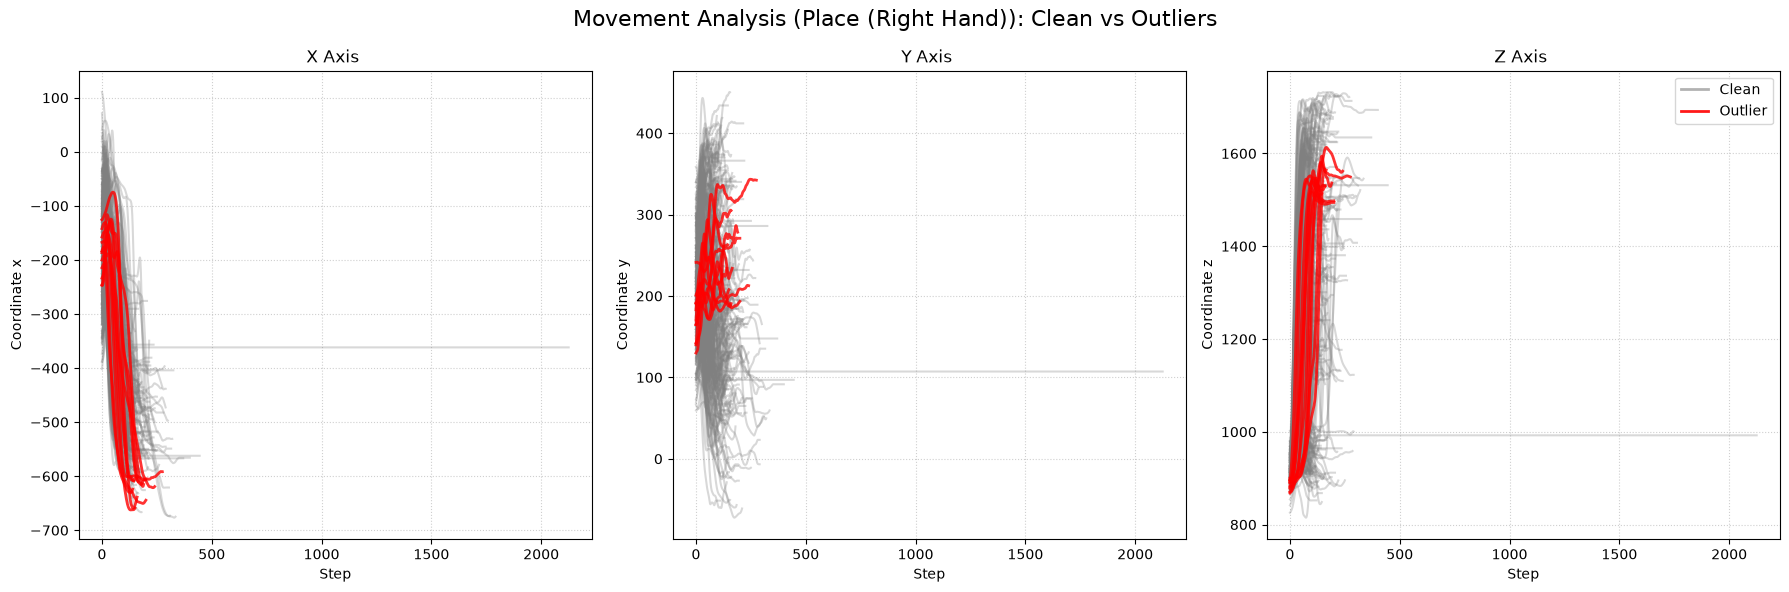

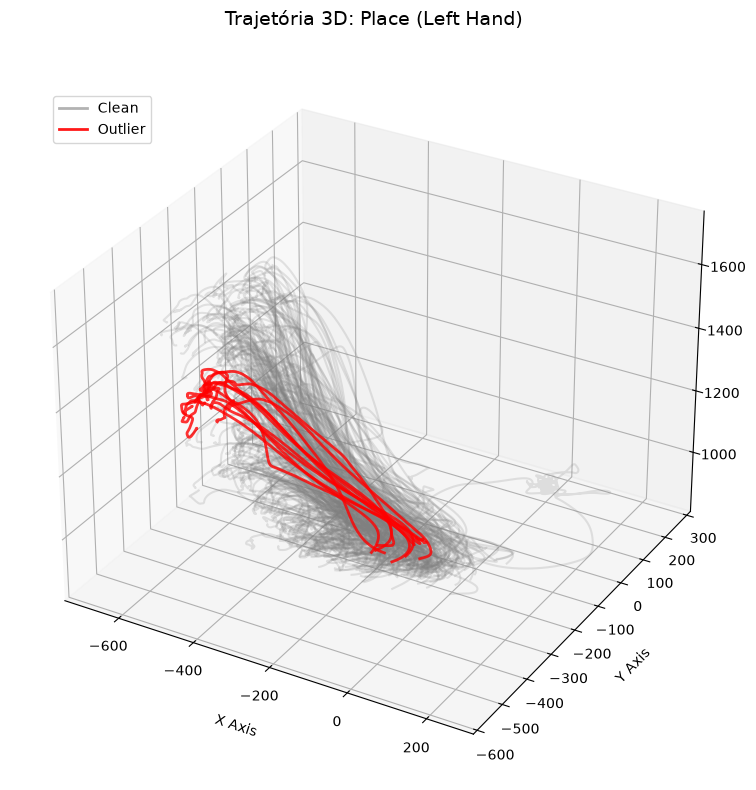

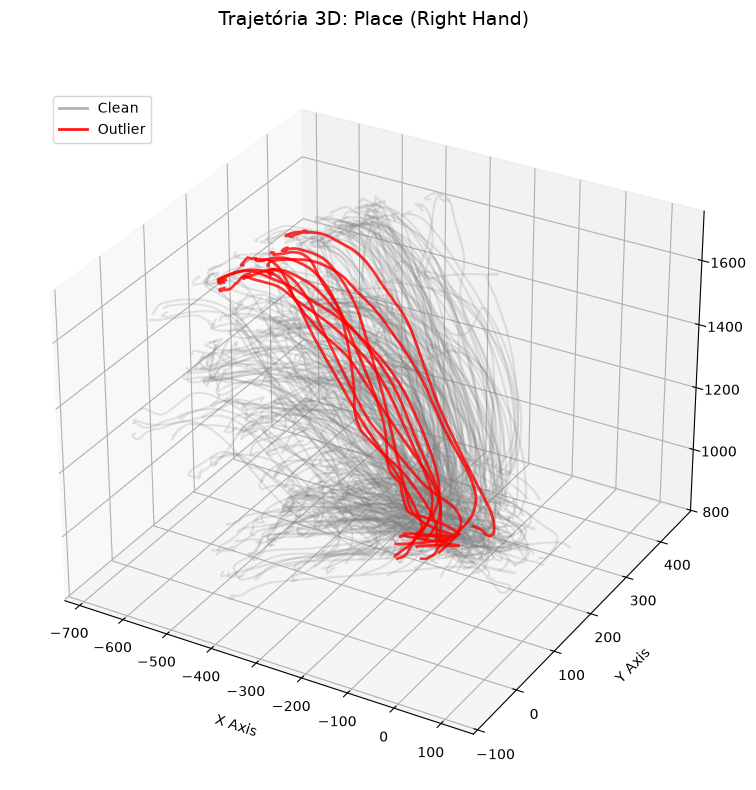

In [43]:
plot_movement_data(
    clean_data=X_movement_clean[:, :, 6:9],       
    outlier_data=X_movement_outliers[:, :, 6:9],  
    target_movement=f"{TARGET_MOVEMENT} (Left Hand)"
)

plot_movement_data(
    clean_data=X_movement_clean[:, :, 15:18],       
    outlier_data=X_movement_outliers[:, :, 15:18],  
    target_movement=f"{TARGET_MOVEMENT} (Right Hand)"
)

# 

plot_movement_data_3d(
    clean_data=X_movement_clean[:, :, 6:9],       
    outlier_data=X_movement_outliers[:, :, 6:9],  
    target_movement=f"{TARGET_MOVEMENT} (Left Hand)"
)
plot_movement_data_3d(
    clean_data=X_movement_clean[:, :, 15:18],       
    outlier_data=X_movement_outliers[:, :, 15:18],  
    target_movement=f"{TARGET_MOVEMENT} (Right Hand)"
)
